In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

from scipy.stats import ttest_1samp
import warnings, os, math
warnings.filterwarnings('ignore')


# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def load_long_zscores(base_dir,
                      csv_rel_path=("data_es", "es", "rois_analysis.csv"),
                      sep=';'):
    """
    Load ROI z-scores from multiple subjects and return a long-format DataFrame.

    Parameters
    ----------
    base_dir : str
        Base directory containing subject folders.
    csv_rel_path : tuple
        Relative path to the CSV inside each subject folder.
    sep : str
        CSV separator.

    Returns
    -------
    pd.DataFrame
        Long-format dataframe with columns:
        SUBJECT, ROI_NAME, HEMI, ZSCORE
    """

    dfs = []

    for subj in sorted(os.listdir(base_dir)):
        subj_path = os.path.join(base_dir, subj)

        if not os.path.isdir(subj_path):
            continue

        csv_path = os.path.join(subj_path, *csv_rel_path)

        if not os.path.exists(csv_path):
            continue

        df = pd.read_csv(csv_path, sep=sep)

        long_df = pd.DataFrame({
            'SUBJECT': subj,
            'ROI_NAME': df['ROI_NAME'],
            'ZSCORE_LH': df['ZSCORE_LH'],
            'ZSCORE_RH': df['ZSCORE_RH']
        })

        long_df = long_df.melt(
            id_vars=['SUBJECT', 'ROI_NAME'],
            value_vars=['ZSCORE_LH', 'ZSCORE_RH'],
            var_name='HEMI',
            value_name='ZSCORE'
        )

        long_df['HEMI'] = long_df['HEMI'].str.replace('ZSCORE_', '', regex=False)

        dfs.append(long_df)

    if not dfs:
        raise ValueError("No CSV files were found.")

    return pd.concat(dfs, ignore_index=True)

In [ ]:
def plot_zscore_hist(ax, data,
                     bins=15,
                     x_range=(-3, 3),
                     title=None):
    data = data.dropna()

    ax.hist(
        data,
        bins=bins,
        range=x_range,
        alpha=0.8
    )

    ax.axvline(0, linestyle='--', linewidth=1)

    if title is not None:
        ax.set_title(title, fontsize=9)

    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)



In [ ]:
def plot_hist_grid(df_wide,
                   n_cols=6,
                   bins=15,
                   x_range=(-3, 3),
                   figsize_per_subplot=(4, 3)):
    """
    Plot a grid of z-score histograms for each column in df_wide.
    """

    cols = df_wide.columns
    n = len(cols)

    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_per_subplot[0] * n_cols,
                 figsize_per_subplot[1] * n_rows),
        sharex=True,
        sharey=True
    )

    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        plot_zscore_hist(
            ax,
            df_wide[col],
            bins=bins,
            x_range=x_range,
            title=col
        )

    # apagar subplots vacíos
    for ax in axes[len(cols):]:
        ax.axis('off')

    fig.supxlabel("Z-score")
    fig.supylabel("Frecuencia")

    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp, wilcoxon

def compute_roi_stats(df_wide, min_n=10):
    """
    One-sample stats vs 0 for each ROI:
    - Mean
    - t-test (one-sided)
    - Wilcoxon (one-sided)
    - Cohen's d
    """

    rows = []

    for roi in df_wide.columns:
        data = df_wide[roi].dropna()
        n = len(data)

        if n < min_n:
            continue

        mean_z = data.mean()
        std_z = data.std(ddof=1)

        # t-test (one-sided)
        tstat, pval_t = ttest_1samp(data, 0.0, alternative="greater")

        # Wilcoxon (one-sided, robust)
        try:
            wstat, pval_w = wilcoxon(data, alternative="greater")
        except ValueError:
            wstat, pval_w = np.nan, np.nan

        # Cohen's d (one-sample)
        cohen_d = mean_z / std_z if std_z > 0 else np.nan

        rows.append({
            "Region": roi,
            "N": n,
            "MEAN_Z": mean_z,
            "STD_Z": std_z,
            "COHEN_D": cohen_d,
            "TSTAT": tstat,
            "PVAL_T": pval_t,
            "WSTAT": wstat,
            "PVAL_W": pval_w
        })

    return pd.DataFrame(rows)


In [ ]:
from statsmodels.stats.multitest import multipletests

def add_fdr(df, alpha=0.05):
    """
    Add FDR-corrected p-values to a ROI-level DataFrame.
    """

    reject, pval_fdr, _, _ = multipletests(
        df["PVAL_TWO"],
        alpha=alpha,
        method="fdr_bh"
    )

    df = df.copy()
    df["PVAL_FDR"] = pval_fdr
    df["FDR_SIG"] = reject

    return df

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_1samp, wilcoxon

def compute_roi_stats(df_wide, min_n=10):
    """
    One-sample stats vs 0 for each ROI:
    - Mean
    - t-test (one-sided)
    - Wilcoxon (one-sided)
    - Cohen's d
    """

    rows = []

    for roi in df_wide.columns:
        data = df_wide[roi].dropna()
        n = len(data)

        if n < min_n:
            continue

        mean_z = data.mean()
        median_z = data.median()
        std_z = data.std(ddof=1)

        # t-test (one-sided)
        tstat, pval_two = ttest_1samp(data, 0.0)  # two-sided por defecto

        pval_one = pval_two / 2

        # Wilcoxon
        try:
           wstat, pval_w = wilcoxon(data, alternative="two-sided")
        except ValueError:
            wstat, pval_w = np.nan, np.nan

        # Cohen's d (one-sample)
        cohen_d = mean_z / std_z if std_z > 0 else np.nan

        rows.append({
            "Region": roi,
            "N": n,
            "MEAN_Z": mean_z,
            "MEDIAN_Z": median_z,
            "STD_Z": std_z,
            "COHEN_D": cohen_d,
            "TSTAT": tstat,
            "PVAL_T": pval_one,
            "WSTAT": wstat,
            "PVAL_W": pval_w
        })

    return pd.DataFrame(rows)


In [ ]:
def classify_effect(df):
    """
    Classify ROIs as HIPER or HIPO based on mean z-score.
    """

    df = df.copy()

    df["Effect"] = np.where(
        df["MEAN_Z"] > 0,
        "HIPER",
        "HIPO"
    )

    return df


In [ ]:
def add_percentage_extreme_column(
    df_all_covid,
    df_wide,
    threshold=1.96,
    new_col="PERC_1_96"
):
    """
    Adds a column with the percentage of subjects showing extreme z-scores:
    - HIPER  -> z >  threshold
    - HIPO   -> z < -threshold

    Parameters
    ----------
    df_all_covid : DataFrame
        ROI-level stats, must contain columns ['Region', 'Effect']
    df_wide : DataFrame
        Wide dataframe with z-scores (rows = subjects, columns = ROIs)
    threshold : float
        Z-score threshold (default = 1.96)
    new_col : str
        Name of the new column to add

    Returns
    -------
    DataFrame
        df_all_covid with the new percentage column added
    """

    percentages = []

    for _, row in df_all_covid.iterrows():
        roi = row["Region"]
        effect = row["Effect"]

        if roi not in df_wide.columns:
            percentages.append(np.nan)
            continue

        data = df_wide[roi].dropna()

        if len(data) == 0:
            percentages.append(np.nan)
            continue

        if effect == "HIPER":
            perc = (data > threshold).mean() * 100
        elif effect == "HIPO":
            perc = (data < -threshold).mean() * 100
        else:
            perc = np.nan

        percentages.append(perc)

    df_all_covid[new_col] = percentages

    return df_all_covid


In [ ]:
paths_informes_controles = "/content/drive/MyDrive/NeurocloudPET/InformesNeurocloudControl"
paths_informes_covid =  "/content/drive/MyDrive/NeurocloudPET/InformesNeurocloud"
paths_informes_fleni = "/content/drive/MyDrive/NeurocloudPET/InformesNeurocloudFleni"

out_dir = "/content/drive/MyDrive/NeurocloudPET/analysis_outputs/A_within_group_zscores"
os.makedirs(out_dir, exist_ok=True)

In [ ]:
df_all_long_controles = load_long_zscores(paths_informes_controles)
df_all_long_covid = load_long_zscores(paths_informes_covid)
df_all_long_fleni = load_long_zscores(paths_informes_fleni)

In [ ]:
df_wide_covid = df_all_long_covid.pivot_table(
    index='SUBJECT',
    columns=['ROI_NAME', 'HEMI'],
    values='ZSCORE'
)

df_wide_covid.columns = [
    f"{roi}_{hemi}" for roi, hemi in df_wide_covid.columns
]

In [ ]:
rename_dict = {
    "Hipocampo": "Hippocampus",
    "Amigdala": "Amygdala",
    "Temporal anterior medial": "Anterior Medial Temporal Lobe",
    "Temporal anterior lateral": "Anterior Lateral Temporal Lobe",
    "Parahipocampo": "Parahippocampal Gyrus",
    "Temporal superior zona posterior": "Posterior Superior Temporal Gyrus", # Chequear
    "Temporal medio e inferior": "Middle and Inferior Temporal Gyrus",
    "Giro fusiforme": "Fusiform Gyrus",
    "Primer giro temporal zona anterior": "Anterior Superior Temporal Gyrus",
    "Temporal posterior": "Posterior Temporal Lobe",
    "Remanente lateral del lobulo occipital": "Lateral Remainder of the Occipital Lobe",
    "Giro lingual": "Lingual Gyrus",
    "Cuneus": "Cuneus",
    "Parte anterior del cingulo": "Anterior Cingulate Gyrus",
    "Giro Frontal medial": "Middle Frontal Gyrus",
    "Giro precentral": "Precentral Gyrus",
    "Giro recto": "Straight Gyrus",
    "Giro orbitario anterior": "Anterior Orbital Gyrus",
    "Giro frontal inferior area de Brocca": "Inferior Frontal Gyrus",
    "Giro frontal superior": "Superior Frontal Gyrus",
    "Giro orbitario medial": "Medial Orbital Gyrus",
    "Giro orbitario lateral": "Lateral Orbital Gyrus",
    "Giro orbitario posterior": "Posterior Orbital Gyrus",
    "Cingulado anterior area subgenual": "Subgenual Frontal Cortex", # Cingulate?
    "Parte posterior del cingulo": "Posterior Cingulate Gyrus",
    "Remanente lateral inferior del lobulo parietal": "Inferior Lateral Remainder\n of the Parietal Lobe",
    "Giro postcentral": "Postcentral Gyrus",
    "Cerebelo": "Cerebellum",
    "Insula": "Insula",
    "Nucleos caudados": "Caudate Nucleus",
    "Putamenes": "Putamen",
    "Talamos": "Thalamus",
    "Precuneus": "Precuneus"
}

def rename_brain_regions(df, rename_dict):
    new_cols = []

    for col in df.columns:
        hemi = ""
        base = col

        if col.endswith("_RH"):
            hemi = "Right "
            base = col[:-3]
        elif col.endswith("_LH"):
            hemi = "Left "
            base = col[:-3]

        base_translated = rename_dict.get(base, base)
        new_cols.append(hemi + base_translated)

    df.columns = new_cols
    return df


df_wide_covid = rename_brain_regions(df_wide_covid, rename_dict)

df_wide_covid

,Left Amygdala,Right Amygdala,Left Cerebellum,Right Cerebellum,Left Subgenual frontal Cortex,Right Subgenual frontal Cortex,Left Cuneus,Right Cuneus,Left Middle Frontal Gyrus,Right Middle Frontal Gyrus,...,Left Anterior lateral temporal lobe,Right Anterior lateral temporal lobe,Left Anterior medial temporal lobe,Right Anterior medial temporal lobe,Left Middle and inferior temporal gyrus,Right Middle and inferior temporal gyrus,Left Posterior temporal lobe,Right Posterior temporal lobe,Left Posterior superior temporal gyrus,Right Posterior superior temporal gyrus
SUBJECT,,,,,,,,,,,,,,,,,,,,,
CP0023,0.2847,0.2808,-0.8153,-0.8672,-0.0969,0.3154,0.4723,-0.0722,1.6876,0.9014,...,0.1407,0.1263,-0.0672,0.0069,0.0849,-0.8024,0.0978,-0.2524,0.4714,0.2199
CP0024,0.0736,0.2325,-0.5066,-0.6444,-0.0255,-0.1081,-0.5481,-0.9948,-0.3130,0.1559,...,-1.4112,-1.2496,0.1405,0.3357,-1.1571,-1.4486,0.1265,-0.4022,-0.0625,-0.2230
CP0027,-0.6493,-0.3485,-0.2003,-0.4249,1.7938,1.5613,-1.0448,-1.2642,1.4887,1.0951,...,0.2914,0.3364,0.3154,0.3487,-0.1887,0.2459,-0.2056,0.3785,-0.4569,-0.4704
CP0031,1.7259,1.4569,0.1888,0.2663,3.2012,3.5026,-0.5620,-0.7042,0.6629,0.6224,...,-0.1045,-0.0463,0.7537,0.5987,-0.6532,0.0328,0.4744,0.9897,1.2425,1.7700
CP0037,0.2065,0.3588,-0.2555,-0.2926,2.0335,1.2649,0.0689,0.0093,0.9024,0.6924,...,-0.2631,-0.1489,0.7518,0.3057,0.0879,-0.0292,0.5376,0.3832,-0.5009,-0.4428
CP0042,0.7564,1.0951,0.3999,0.0909,1.3007,1.9614,1.0232,0.8117,0.7878,0.3371,...,1.0026,0.0595,0.6693,0.6606,0.7469,0.0954,1.3955,0.4507,1.3965,1.2728
CP0043,0.0951,0.4654,0.2182,0.2549,0.3263,0.6559,0.2647,-0.1096,0.7532,0.8670,...,-1.5743,-1.3292,0.0895,0.2708,-0.9968,-0.7720,-0.3190,-0.5031,-0.3941,-0.3710
CP0055,0.0588,0.5708,0.0086,-0.0336,-0.6756,0.5161,0.0155,-0.4478,1.8490,0.4171,...,0.5653,-0.0470,0.0450,0.1553,0.0178,-0.0850,0.4667,0.0354,0.9368,0.3780
CP0062,1.4121,1.1159,0.8962,1.1978,1.9289,1.8230,-1.3131,-1.5000,1.4003,0.9113,...,0.1065,0.6237,1.5955,1.8814,0.3441,0.3134,0.4379,0.3759,-0.4893,0.2776


In [ ]:
df_all_covid = compute_roi_stats(df_wide_covid)
df_all_covid = classify_effect(df_all_covid)

In [ ]:
df_all_covid.to_csv("df_all_covid.csv", index=False)

In [ ]:
df_hyper_sig = (
    df_all_covid
    .query("PVAL_T < 0.05 and Effect == 'HIPER'")
    .sort_values("COHEN_D", ascending=False)
)

df_hyper_sig

,Region,N,MEAN_Z,MEDIAN_Z,STD_Z,COHEN_D,TSTAT,PVAL_T,WSTAT,PVAL_W,Effect
8,Left Middle Frontal Gyrus,27,1.186915,0.9622,0.753495,1.575213,8.185048,5.745091e-09,2.0,4.470348e-08,HIPER
9,Right Middle Frontal Gyrus,27,0.892659,0.8851,0.568947,1.568967,8.152589,6.194739e-09,2.0,4.470348e-08,HIPER
11,Right Inferior frontal Gyrus,27,0.749552,0.7219,0.558701,1.341599,6.971151,1.055904e-07,14.0,1.639128e-06,HIPER
10,Left Inferior frontal Gyrus,27,0.810070,0.8931,0.608939,1.330298,6.912430,1.221303e-07,11.0,8.195639e-07,HIPER
13,Right Superior frontal Gyrus,27,0.855885,0.8034,0.647288,1.322263,6.870682,1.354764e-07,5.0,1.490116e-07,HIPER
41,Right Anterior cingulate gyrus,27,0.865796,0.8183,0.690518,1.253836,6.515121,3.303717e-07,8.0,3.725290e-07,HIPER
40,Left Anterior cingulate gyrus,27,0.838193,0.8074,0.732505,1.144282,5.945863,1.415564e-06,11.0,8.195639e-07,HIPER
35,Right Insula,27,1.001100,1.1695,0.878591,1.139438,5.920695,1.510689e-06,20.0,5.528331e-06,HIPER
34,Left Insula,27,0.829419,0.8259,0.810855,1.022894,5.315113,7.328701e-06,26.0,1.592934e-05,HIPER
12,Left Superior frontal Gyrus,27,0.671296,0.5233,0.678533,0.989334,5.140731,1.159438e-05,28.0,2.208352e-05,HIPER


In [ ]:
df_hypo_sig = (
    df_all_covid
    .query("PVAL_T < 0.05 and Effect == 'HIPO'")
    .sort_values("COHEN_D", ascending=True)
)

df_hypo_sig

,Region,N,MEAN_Z,MEDIAN_Z,STD_Z,COHEN_D,TSTAT,PVAL_T,WSTAT,PVAL_W,Effect
48,Left Putamen,27,-0.600711,-0.6733,0.519881,-1.155478,-6.004042,0.000001,26.0,0.000016,HIPO
49,Right Putamen,27,-0.636011,-0.6990,0.591356,-1.075513,-5.588531,0.000004,26.0,0.000016,HIPO
51,Right Lateral remainder of the occipital lobe,27,-0.639074,-0.7067,0.666445,-0.958930,-4.982744,0.000018,34.0,0.000055,HIPO
57,Right Anterior lateral temporal lobe,27,-0.791393,-0.7244,0.975353,-0.811391,-4.216109,0.000133,48.0,0.000339,HIPO
50,Left Lateral remainder of the occipital lobe,27,-0.463748,-0.4711,0.639003,-0.725737,-3.771041,0.000423,58.0,0.001021,HIPO
56,Left Anterior lateral temporal lobe,27,-0.581485,-0.5311,0.872799,-0.666230,-3.461833,0.000934,74.0,0.004613,HIPO
61,Right Middle and inferior temporal gyrus,27,-0.468819,-0.3328,0.974234,-0.481217,-2.500479,0.009518,97.0,0.026231,HIPO
22,Left Medial orbital Gyrus,27,-0.292959,-0.4490,0.714040,-0.410284,-2.131898,0.021315,109.0,0.055203,HIPO
60,Left Middle and inferior temporal gyrus,27,-0.314822,-0.3665,0.790604,-0.398205,-2.069133,0.024305,113.0,0.069227,HIPO
19,Right Anterior orbital Gyrus,27,-0.313719,-0.2708,0.791358,-0.396431,-2.059915,0.024774,108.0,0.052081,HIPO


In [ ]:
df_all_covid = add_percentage_extreme_column(
    df_all_covid,
    df_wide_covid,
    threshold=1.96
)

In [ ]:
df_all_covid.to_csv(
    "/content/drive/MyDrive/NeurocloudPET/df_all_covid.csv",
    index=False
)

df_all_covid





,Region,N,MEAN_Z,MEDIAN_Z,STD_Z,COHEN_D,TSTAT,PVAL_T,WSTAT,PVAL_W,Effect,PERC_1_96
0,Left Amygdala,27,0.185270,0.0840,0.618729,0.299437,1.555919,0.065909,116.0,0.081489,HIPER,0.000000
1,Right Amygdala,27,0.255230,0.2325,0.567372,0.449845,2.337465,0.013693,87.0,0.013011,HIPER,0.000000
2,Left Cerebellum,27,-0.150437,-0.1799,0.583775,-0.257697,-1.339032,0.096075,134.0,0.193680,HIPO,0.000000
3,Right Cerebellum,27,-0.210604,-0.1045,0.629246,-0.334692,-1.739112,0.046922,115.0,0.077226,HIPO,0.000000
4,Left Subgenual frontal Cortex,27,0.598863,0.3263,1.034290,0.579009,3.008617,0.002882,81.0,0.008215,HIPER,11.111111
...,...,...,...,...,...,...,...,...,...,...,...,...
61,Right Middle and inferior temporal gyrus,27,-0.468819,-0.3328,0.974234,-0.481217,-2.500479,0.009518,97.0,0.026231,HIPO,7.407407
62,Left Posterior temporal lobe,27,0.098048,0.0978,0.614192,0.159638,0.829502,0.207186,156.0,0.441044,HIPER,0.000000
63,Right Posterior temporal lobe,27,-0.045993,0.1300,0.746391,-0.061620,-0.320187,0.375693,188.0,0.990573,HIPO,3.703704
64,Left Posterior superior temporal gyrus,27,-0.022515,-0.0655,0.590209,-0.038147,-0.198218,0.422208,159.0,0.484606,HIPO,0.000000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def volcano_plot(
    df,
    effect_col="MEDIAN_Z",
    pval_col="PVAL_FDR",
    alpha=0.05,
    sesoi=0.5,
    X_label = "Median z-score",
    title="Volcano plot (Wilcoxon)",
    figsize=(8, 6),

):
    """
    Volcano plot for ROI-level statistics.
    """

    df = df.copy()

    # Evitar problemas con log(0)
    df[pval_col] = df[pval_col].replace(0, np.nan)

    x = df[effect_col]
    y = -np.log10(df[pval_col])

    # Criterio combinado
    # significant = (df[pval_col] < alpha) & (np.abs(df[effect_col]) >= sesoi)
    significant = (df[pval_col] < alpha)


    plt.figure(figsize=figsize)

    # Puntos no relevantes
    plt.scatter(
        x[~significant],
        y[~significant],
        color="lightgray",
        alpha=0.7,
        label="Not selected"
    )

    # Puntos relevantes
    plt.scatter(
        x[significant],
        y[significant],
        color="crimson",
        alpha=0.9,
        label="Significant"
    )

    # Líneas de corte
    plt.axhline(-np.log10(alpha), color="black", linestyle="--", linewidth=1)
    plt.axvline(+sesoi, color="black", linestyle="--", linewidth=1)
    plt.axvline(-sesoi, color="black", linestyle="--", linewidth=1)

    plt.xlabel(X_label)
    plt.ylabel("-log10(p-value)")
    plt.title(title)
    plt.legend(frameon=False)

    plt.tight_layout()
    plt.show()


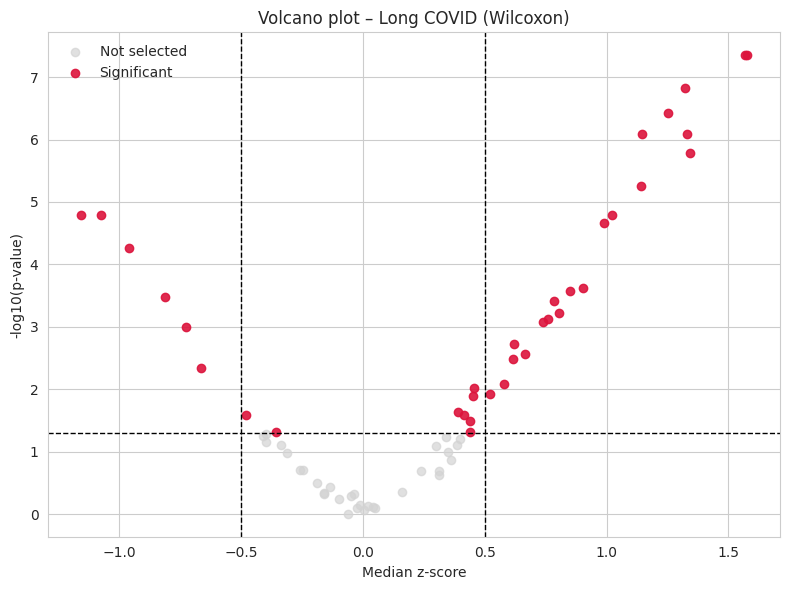

In [ ]:
volcano_plot(
    df=df_all_covid,
    effect_col="COHEN_D",
    pval_col="PVAL_W",
    alpha=0.05,
    sesoi=0.5,
    title="Volcano plot – Long COVID (Wilcoxon)"
)


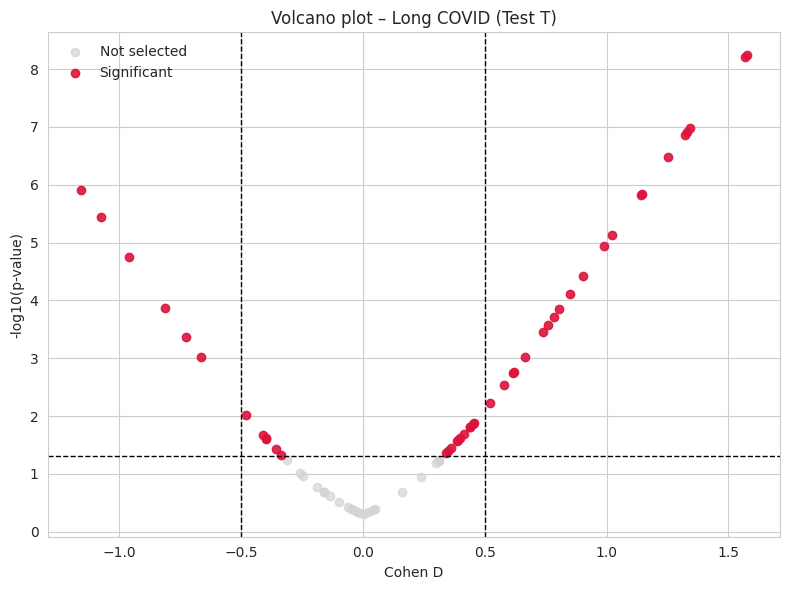

In [ ]:
volcano_plot(
    df=df_all_covid,
    effect_col="COHEN_D",
    pval_col="PVAL_T",
    alpha=0.05,
    sesoi=0.5,
    X_label = "Cohen D",
    title="Volcano plot – Long COVID (Test T)"
)


In [ ]:
def forest_plot_hyper_hypo(
    df,
    p_col="PVAL_T",
    effect_col="COHEN_D",
    std_col="STD_Z",
    n_col="N",
    alpha=0.05,
    sesoi=0.5,
    max_regions=25,
    title="Forest plot – Long COVID"
):

    import numpy as np
    import matplotlib.pyplot as plt

    # -----------------------------------
    # FILTRAR SOLO SIGNIFICATIVAS POR P
    # -----------------------------------
    df_sig = df[(df[p_col] < alpha) & (np.abs(df[effect_col]) >= sesoi)].copy()


    # Separar por signo
    df_hyper = (
        df_sig[df_sig[effect_col] > 0]
        .sort_values(effect_col, ascending=False)
        .head(max_regions)
    )

    df_hypo = (
        df_sig[df_sig[effect_col] < 0]
        .sort_values(effect_col, ascending=True)
        .head(max_regions)
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, max(len(df_hyper), len(df_hypo)) * 0.25 + 2),
        sharex=True
    )

    for ax, df_plot, panel_title, sig_color in zip(
        axes,
        [df_hyper, df_hypo],
        ["A) Hypermetabolism", "B) Hypometabolism"],
        ["tab:red", "tab:blue"]
    ):

        if df_plot.empty:
            ax.set_title(panel_title)
            continue

        se = df_plot[std_col] / np.sqrt(df_plot[n_col])
        ci_low = df_plot[effect_col] - 1.96 * se
        ci_high = df_plot[effect_col] + 1.96 * se

        y_pos = np.arange(len(df_plot))

        # criterio por tamaño de efecto
        big_effect = np.abs(df_plot[effect_col]) >= sesoi
        small_effect = ~big_effect

        # --- gris (p < alpha pero d pequeño)
        ax.errorbar(
            df_plot.loc[small_effect, effect_col],
            y_pos[small_effect],
            xerr=[
                df_plot.loc[small_effect, effect_col] - ci_low[small_effect],
                ci_high[small_effect] - df_plot.loc[small_effect, effect_col]
            ],
            fmt="o",
            color="lightgray",
            ecolor="lightgray",
            capsize=2,
            markersize=3,
            zorder=1
        )

        # --- color (p < alpha y d grande)
        ax.errorbar(
            df_plot.loc[big_effect, effect_col],
            y_pos[big_effect],
            xerr=[
                df_plot.loc[big_effect, effect_col] - ci_low[big_effect],
                ci_high[big_effect] - df_plot.loc[big_effect, effect_col]
            ],
            fmt="o",
            color=sig_color,
            ecolor=sig_color,
            capsize=2,
            markersize=4,
            zorder=2
        )

        ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
        ax.axvline(sesoi, linestyle=":", color="black", linewidth=0.8)
        ax.axvline(-sesoi, linestyle=":", color="black", linewidth=0.8)

        ax.set_yticks(y_pos)
        ax.set_yticklabels(df_plot["Region"], fontsize=7)
        ax.invert_yaxis()
        ax.set_title(panel_title, fontsize=10)
        ax.grid(axis="x", alpha=0.25)

    fig.supxlabel("Cohen's d")
    fig.suptitle(title, fontsize=12)

    plt.tight_layout()
    plt.show()



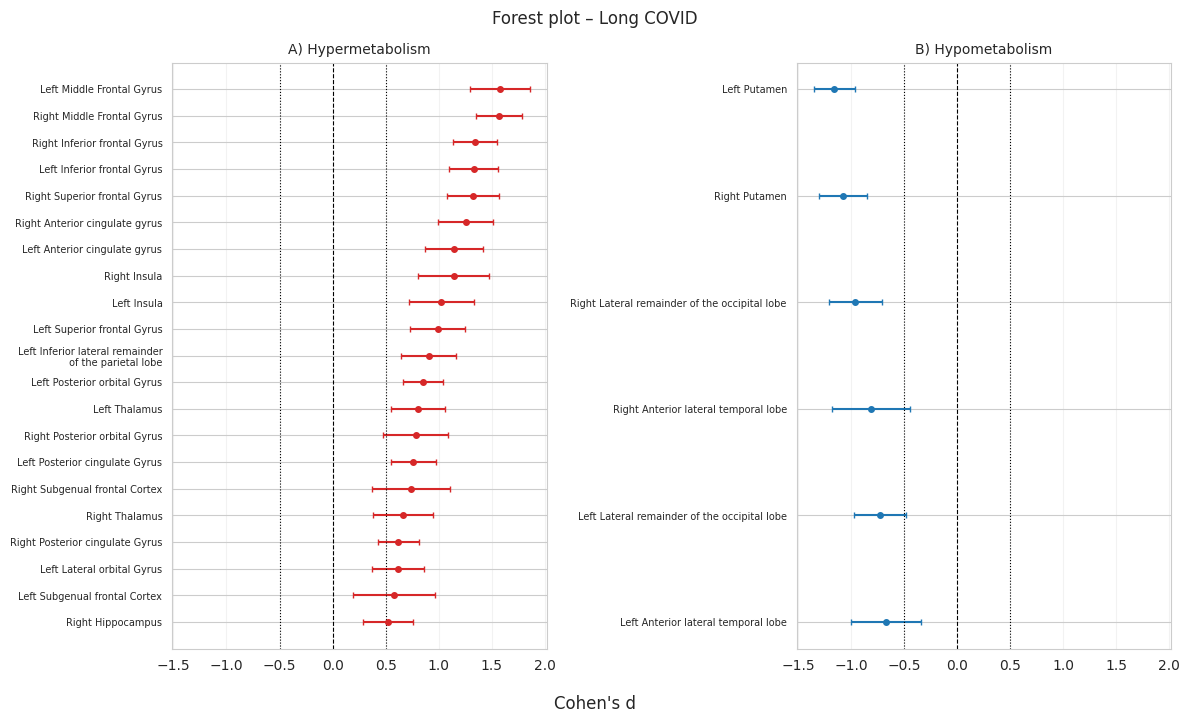

In [ ]:
forest_plot_hyper_hypo(
    df_all_covid,
    p_col="PVAL_T",          # o "PVAL_W" si querés Wilcoxon
    effect_col="COHEN_D",
    std_col="STD_Z",
    n_col="N",
    alpha=0.05,
    sesoi=0.5,
    max_regions=50,
    title="Forest plot – Long COVID"
)
